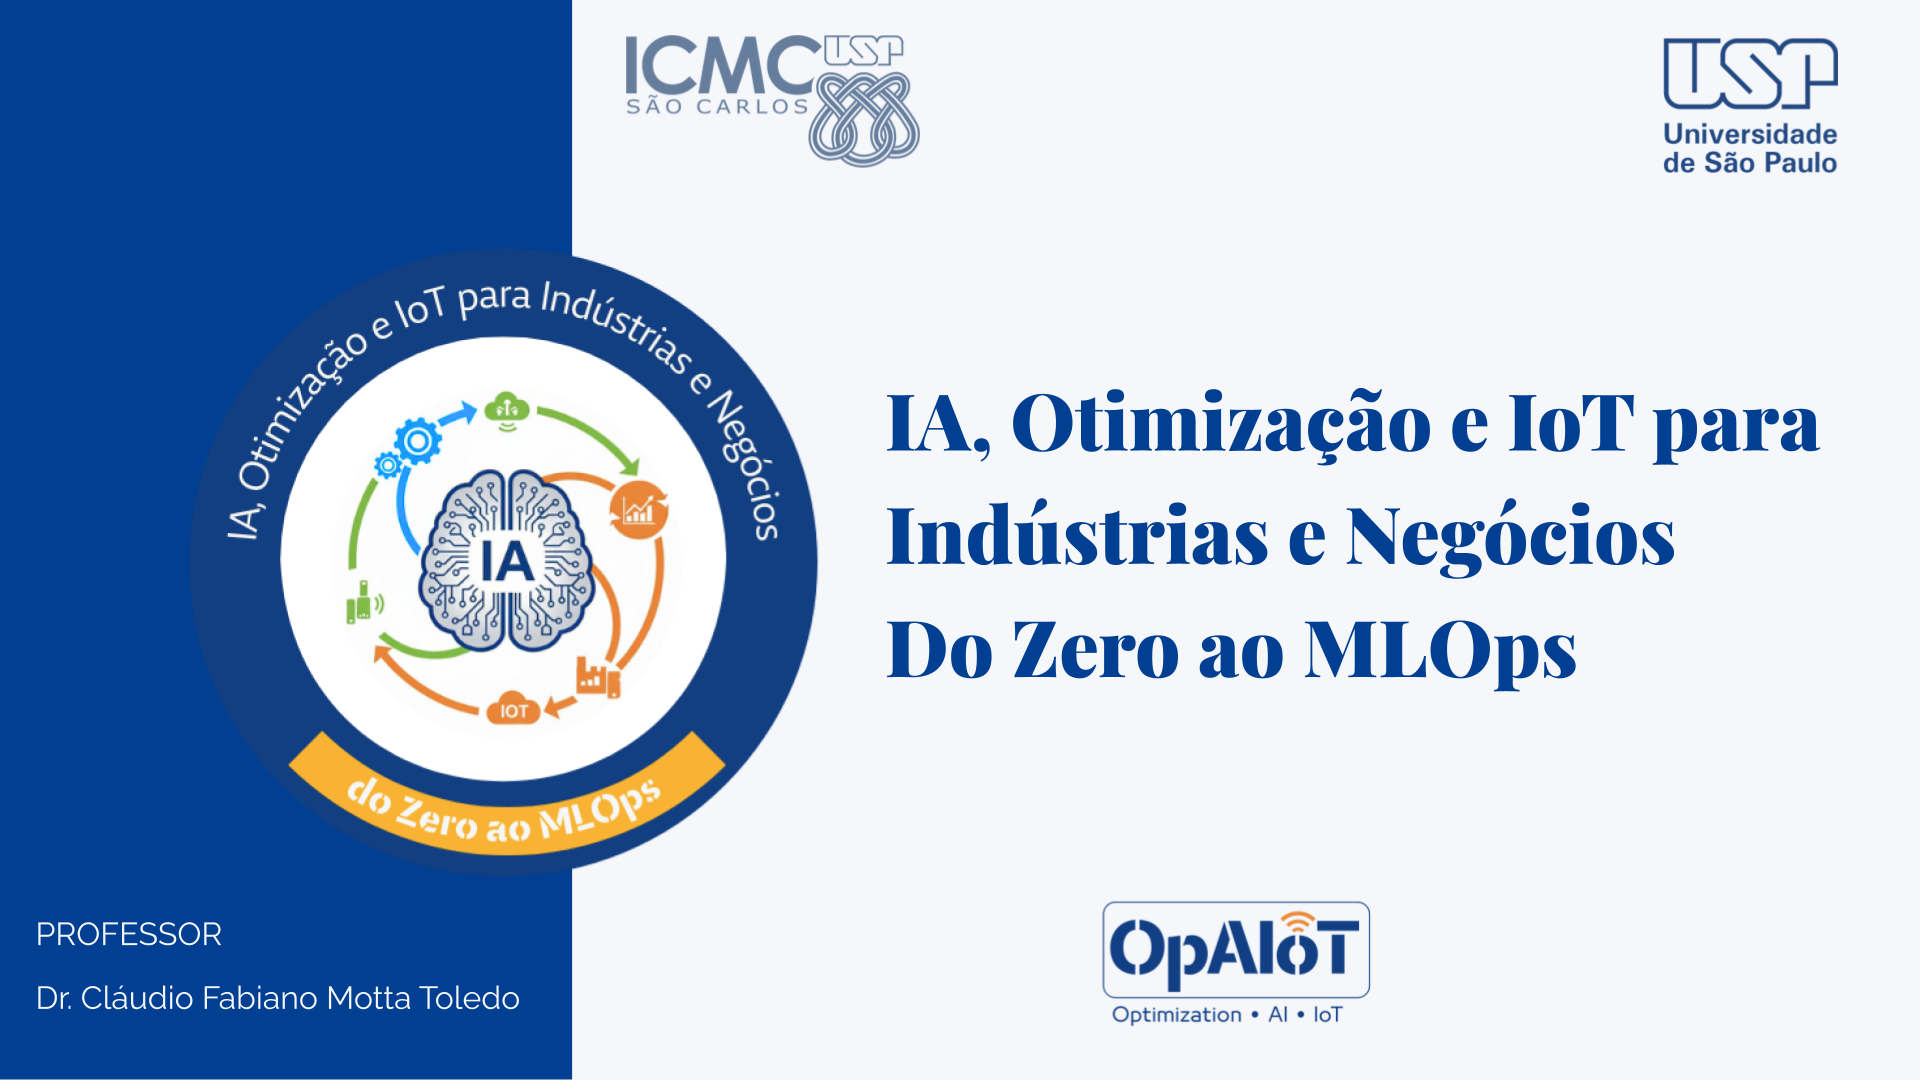

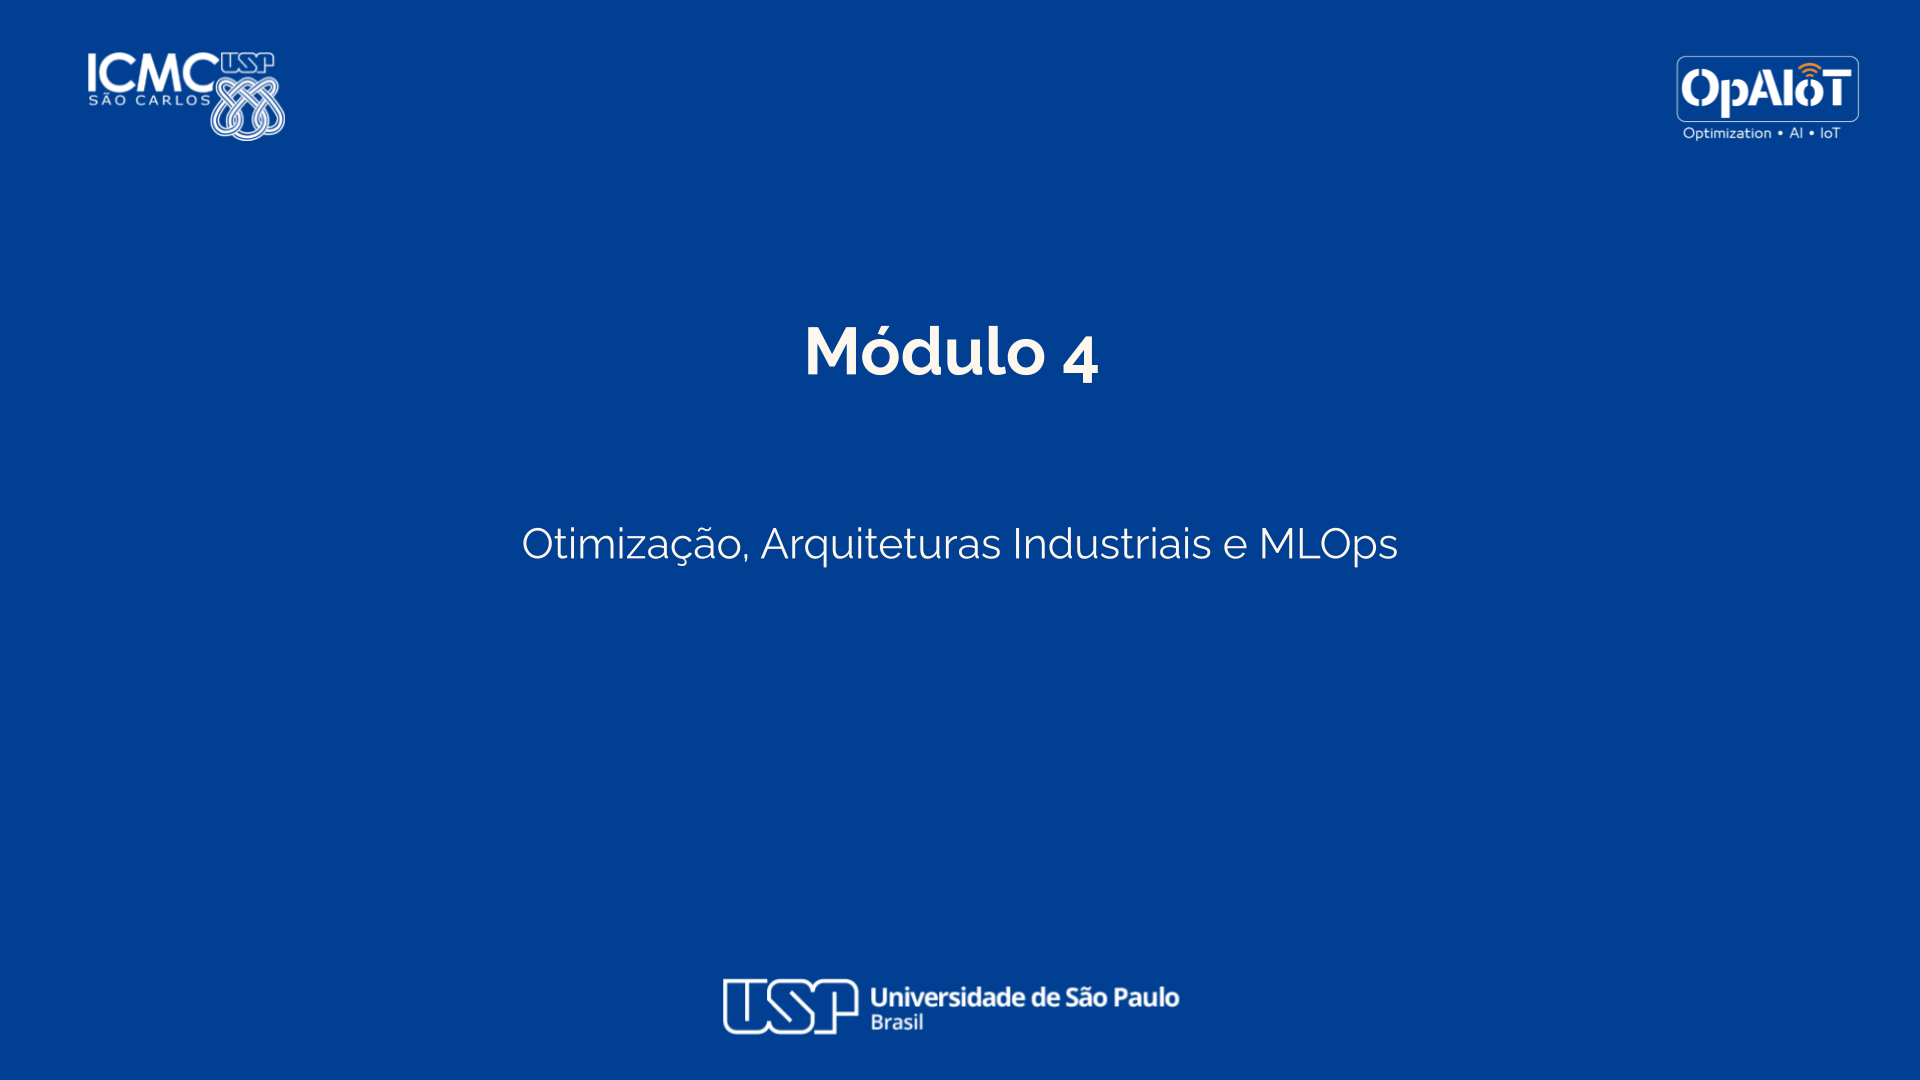

# Prática guiada — Programação Inteira Mista e Otimização Multiobjetivo com Pyomo

Esta prática consolida os conceitos das aulas sobre **Programação Inteira Mista (PIM)**, **dominância/Pareto** e **métodos de otimização multiobjetivo** usando um único caso industrial.

## Caso industrial

Uma empresa precisa atender uma demanda mínima usando diferentes linhas produtivas. Cada linha tem:

- capacidade produtiva;
- custo fixo de ativação;
- custo variável de produção;
- emissão de CO₂ por unidade produzida;
- impacto no risco operacional, medido pela falta esperada em cenários de demanda.

As decisões são:

$$
x_i = \text{quantidade produzida na linha } i
$$

$$
y_i =
\begin{cases}
1, & \text{se a linha } i \text{ for ativada}\\
0, & \text{caso contrário}
\end{cases}
$$

O notebook mostra como resolver o problema com Pyomo e como analisar trade-offs entre **custo**, **emissões** e **risco**.


## Objetivos da prática

Ao final, você deverá conseguir:

1. construir um modelo de Programação Inteira Mista em Pyomo;
2. interpretar variáveis contínuas e binárias;
4. resolver modelos com diferentes objetivos;


# Parte 0 — Instalação e importação das bibliotecas

Usaremos:

- `pyomo`: biblioteca de modelagem matemática;
- `highspy`: interface Python para o solver HiGHS;
- `pandas`: organização de resultados em tabelas;
- `numpy`: apoio a cálculos numéricos;
- `matplotlib`: criação de gráficos.

No Google Colab, execute a célula abaixo para instalar as bibliotecas necessárias.


In [ ]:
!pip install -q pyomo highspy pandas matplotlib numpy

import pyomo.environ as pyo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import product


# Parte I — Dados do problema

Temos quatro linhas produtivas. Elas representam alternativas com perfis diferentes:

- `L1_eficiente`: menor emissão, mas custo fixo maior;
- `L2_barata`: baixo custo variável, mas maior emissão;
- `L3_flexivel`: perfil intermediário;
- `L4_terceirizada`: baixo custo fixo, mas alto custo variável.

Também definimos cenários de demanda para representar incerteza. A variável `falta[s]` medirá a falta de produção em cada cenário.


In [ ]:
linhas = ["L1_eficiente", "L2_barata", "L3_flexivel", "L4_terceirizada"]

capacidade = {
    "L1_eficiente": 80,
    "L2_barata": 70,
    "L3_flexivel": 60,
    "L4_terceirizada": 50
}

custo_fixo = {
    "L1_eficiente": 4500,
    "L2_barata": 2500,
    "L3_flexivel": 3200,
    "L4_terceirizada": 1000
}

custo_variavel = {
    "L1_eficiente": 42,
    "L2_barata": 35,
    "L3_flexivel": 48,
    "L4_terceirizada": 60
}

emissao = {
    "L1_eficiente": 0.55,
    "L2_barata": 0.95,
    "L3_flexivel": 0.65,
    "L4_terceirizada": 0.80
}

# Demanda mínima que deve ser atendida no planejamento base
demanda_base = 110

# Cenários de demanda usados para representar incerteza e risco operacional
cenarios_demanda = {
    "baixo": 100,
    "base": 110,
    "alto": 130,
    "pico": 150
}

probabilidade = {
    "baixo": 0.20,
    "base": 0.45,
    "alto": 0.25,
    "pico": 0.10
}

# Número máximo de linhas que podem ser ativadas
K_max = 3


## Visualização dos dados

Antes de montar o modelo, vamos visualizar os dados em tabelas.

Observe que não existe uma linha “melhor em tudo”. Algumas são mais baratas, outras mais limpas, outras ajudam mais a aumentar a produção e reduzir risco. Essa diferença gera **trade-offs**.


In [ ]:
df_dados = pd.DataFrame({
    "Linha": linhas,
    "Capacidade": [capacidade[i] for i in linhas],
    "Custo fixo": [custo_fixo[i] for i in linhas],
    "Custo variável": [custo_variavel[i] for i in linhas],
    "Emissão por unidade": [emissao[i] for i in linhas]
})

display(df_dados)

df_cenarios = pd.DataFrame({
    "Cenário": list(cenarios_demanda.keys()),
    "Demanda": list(cenarios_demanda.values()),
    "Probabilidade": [probabilidade[s] for s in cenarios_demanda]
})

display(df_cenarios)


# Parte II — Modelo de Programação Inteira Mista

Agora vamos construir o modelo PIM.

## Variáveis

Quantidade produzida em cada linha:

$$
x_i \geq 0
$$

Ativação da linha:

$$
y_i \in \{0,1\}
$$

Falta de produção no cenário de demanda $s$:

$$
falta_s \geq 0
$$

## Restrições principais

Atender a demanda base:

$$
\sum_i x_i \geq D
$$

Só produzir se a linha for ativada:

$$
x_i \leq M_i y_i
$$

Ativar no máximo $K$ linhas:

$$
\sum_i y_i \leq K
$$

Medir falta de produção em cenários incertos:

$$
falta_s \geq Demanda_s - \sum_i x_i
$$


## Construção do modelo em Pyomo

A função abaixo constrói o modelo, mas ainda não define uma função objetivo específica.

Isso é proposital: usaremos o mesmo modelo para minimizar custo, emissões, risco, soma ponderada, $\varepsilon$-restrições e programação por metas.

O argumento `relaxar_binarias=True` troca $y_i \in \{0,1\}$ por $0 \leq y_i \leq 1$. Isso será usado para ilustrar a relaxação linear.


In [ ]:
def construir_modelo_pim(relaxar_binarias=False, capacidade_bigM=None, max_linhas=K_max):
    m = pyo.ConcreteModel(name="Planejamento_PIM")

    # Conjuntos
    m.I = pyo.Set(initialize=linhas)
    m.S = pyo.Set(initialize=list(cenarios_demanda.keys()))

    # Parâmetros
    m.cap = pyo.Param(m.I, initialize=capacidade)
    m.cf = pyo.Param(m.I, initialize=custo_fixo)
    m.cv = pyo.Param(m.I, initialize=custo_variavel)
    m.em = pyo.Param(m.I, initialize=emissao)
    m.dem = pyo.Param(m.S, initialize=cenarios_demanda)
    m.prob = pyo.Param(m.S, initialize=probabilidade)

    # M usado na restrição de ligação.
    # Por padrão, usamos a capacidade real de cada linha.
    if capacidade_bigM is None:
        capacidade_bigM = capacidade.copy()

    m.M = pyo.Param(m.I, initialize=capacidade_bigM)

    # Variável contínua de produção
    m.x = pyo.Var(m.I, domain=pyo.NonNegativeReals)

    # Variável binária ou relaxada
    if relaxar_binarias:
        m.y = pyo.Var(m.I, bounds=(0, 1))
    else:
        m.y = pyo.Var(m.I, domain=pyo.Binary)

    # Falta de produção em cada cenário
    m.falta = pyo.Var(m.S, domain=pyo.NonNegativeReals)

    # Expressões de desempenho
    m.custo = pyo.Expression(
        expr=sum(m.cf[i] * m.y[i] + m.cv[i] * m.x[i] for i in m.I)
    )

    m.emissoes = pyo.Expression(
        expr=sum(m.em[i] * m.x[i] for i in m.I)
    )

    m.risco = pyo.Expression(
        expr=sum(m.prob[s] * m.falta[s] for s in m.S)
    )

    # Atendimento da demanda base
    m.atende_demanda_base = pyo.Constraint(
        expr=sum(m.x[i] for i in m.I) >= demanda_base
    )

    # Restrição de ligação Big-M: só produz na linha se ela for ativada
    def regra_ligacao(m, i):
        return m.x[i] <= m.M[i] * m.y[i]

    m.ligacao = pyo.Constraint(m.I, rule=regra_ligacao)

    # Capacidade física real da linha
    def regra_capacidade_fisica(m, i):
        return m.x[i] <= m.cap[i]

    m.capacidade_fisica = pyo.Constraint(m.I, rule=regra_capacidade_fisica)

    # No máximo K linhas ativadas
    m.max_linhas = pyo.Constraint(expr=sum(m.y[i] for i in m.I) <= max_linhas)

    # Falta de atendimento em cada cenário
    def regra_falta(m, s):
        return m.falta[s] >= m.dem[s] - sum(m.x[i] for i in m.I)

    m.falta_cenario = pyo.Constraint(m.S, rule=regra_falta)

    return m


## Função auxiliar para resolver o modelo

Usaremos o solver HiGHS via `appsi_highs`.

A função abaixo recebe um modelo Pyomo e chama o solver. Ela retorna o objeto com informações sobre a solução.


In [ ]:
def resolver(modelo, tee=False):
    solver = pyo.SolverFactory("appsi_highs")

    if not solver.available(exception_flag=False):
        raise RuntimeError(
            "Solver appsi_highs não disponível. Verifique se pyomo e highspy foram instalados."
        )

    resultado = solver.solve(modelo, tee=tee)
    return resultado


## Funções auxiliares para extrair resultados

Para comparar diferentes soluções, criaremos funções que extraem:

- custo;
- emissões;
- risco;
- produção total;
- produção de cada linha;
- ativação de cada linha.

Isso facilita montar tabelas comparativas ao longo da prática.


In [ ]:
def extrair_resultados(modelo, nome):
    return {
        "nome": nome,
        "custo": pyo.value(modelo.custo),
        "emissoes": pyo.value(modelo.emissoes),
        "risco": pyo.value(modelo.risco),
        "producao_total": sum(pyo.value(modelo.x[i]) for i in linhas),
        **{f"x_{i}": pyo.value(modelo.x[i]) for i in linhas},
        **{f"y_{i}": pyo.value(modelo.y[i]) for i in linhas}
    }


def tabela_solucao(modelo):
    return pd.DataFrame({
        "Linha": linhas,
        "Produção x": [pyo.value(modelo.x[i]) for i in linhas],
        "Ativada y": [pyo.value(modelo.y[i]) for i in linhas],
        "Capacidade": [pyo.value(modelo.cap[i]) for i in linhas],
        "Custo fixo": [pyo.value(modelo.cf[i]) for i in linhas],
        "Custo variável": [pyo.value(modelo.cv[i]) for i in linhas],
        "Emissão por unidade": [pyo.value(modelo.em[i]) for i in linhas]
    })


# Parte III — Resolvendo o PIM minimizando custo

Vamos começar com um único objetivo:

$$
\min \text{Custo}
$$

Esse modelo escolhe a combinação de linhas produtivas que atende a demanda base com menor custo.

Depois vamos observar se essa solução também é boa em emissões e risco.


In [ ]:
m_custo = construir_modelo_pim(relaxar_binarias=False)
m_custo.obj = pyo.Objective(expr=m_custo.custo, sense=pyo.minimize)

resultado = resolver(m_custo)

print("Status:", resultado.solver.status)
print("Condição de término:", resultado.solver.termination_condition)

display(tabela_solucao(m_custo))

print(f"Custo total: {pyo.value(m_custo.custo):.2f}")
print(f"Emissões totais: {pyo.value(m_custo.emissoes):.2f}")
print(f"Risco esperado de falta: {pyo.value(m_custo.risco):.2f}")


# Parte IV - Relaxação Linear e Big-M
## Relaxação linear

Na relaxação linear, trocamos:

$$
y_i \in \{0,1\}
$$

por:

$$
0 \leq y_i \leq 1
$$

Isso pode gerar valores fracionários, como $y_i = 0{,}5$. Essa solução não é uma decisão real, mas é útil para o solver calcular limites no Branch-and-Bound.


In [ ]:
def resolver_custo(relaxar_binarias=False, capacidade_bigM=None):
    m = construir_modelo_pim(
        relaxar_binarias=relaxar_binarias,
        capacidade_bigM=capacidade_bigM
    )
    m.obj = pyo.Objective(expr=m.custo, sense=pyo.minimize)
    resolver(m)
    return m

m_mip = resolver_custo(relaxar_binarias=False)
m_relax = resolver_custo(relaxar_binarias=True)

comparacao = pd.DataFrame({
    "Modelo": ["MIP com binárias", "Relaxação linear"],
    "Custo": [pyo.value(m_mip.custo), pyo.value(m_relax.custo)],
    "Emissões": [pyo.value(m_mip.emissoes), pyo.value(m_relax.emissoes)],
    "Risco": [pyo.value(m_mip.risco), pyo.value(m_relax.risco)]
})

display(comparacao)

df_relax = pd.DataFrame({
    "Linha": linhas,
    "x no MIP": [pyo.value(m_mip.x[i]) for i in linhas],
    "y no MIP": [pyo.value(m_mip.y[i]) for i in linhas],
    "x na relaxação": [pyo.value(m_relax.x[i]) for i in linhas],
    "y na relaxação": [pyo.value(m_relax.y[i]) for i in linhas]
})

display(df_relax)


## Big-M, restrição de ligação e relaxação linear

A restrição de ligação é:

$$
x_i \leq M_i y_i
$$

No nosso modelo, usamos $M_i$ como a capacidade máxima da linha.

Essa restrição significa:

- se $y_i = 0$, então $x_i = 0$;
- se $y_i = 1$, então $x_i$ pode ser positivo até o limite $M_i$.

Essa é uma das estruturas mais comuns em Programação Inteira Mista.

## Big-M exagerado

Agora vamos comparar a relaxação linear com dois valores de $M$:

1. $M$ realista: capacidade da linha;
2. $M$ exagerado: 10000 para todas as linhas.

Mesmo com a restrição de capacidade física impedindo produção irreal, um Big-M exagerado pode enfraquecer a relaxação linear porque permite valores muito pequenos de $y_i$ para “ativar” produção na relaxação.


In [ ]:
M_realista = capacidade.copy()
M_exagerado = {i: 10000 for i in linhas}

m_relax_M_realista = resolver_custo(relaxar_binarias=True, capacidade_bigM=M_realista)
m_relax_M_exagerado = resolver_custo(relaxar_binarias=True, capacidade_bigM=M_exagerado)

df_bigM = pd.DataFrame({
    "Caso": ["M realista", "M exagerado"],
    "Valor da relaxação linear": [
        pyo.value(m_relax_M_realista.custo),
        pyo.value(m_relax_M_exagerado.custo)
    ]
})

display(df_bigM)

df_bigM_y = pd.DataFrame({
    "Linha": linhas,
    "y com M realista": [pyo.value(m_relax_M_realista.y[i]) for i in linhas],
    "y com M exagerado": [pyo.value(m_relax_M_exagerado.y[i]) for i in linhas],
    "x com M realista": [pyo.value(m_relax_M_realista.x[i]) for i in linhas],
    "x com M exagerado": [pyo.value(m_relax_M_exagerado.x[i]) for i in linhas]
})

display(df_bigM_y)


## Discussão sobre Big-M

A ideia central é:

> quando M é muito grande, a relaxação linear fica fraca, permitindo soluções fracionárias artificialmente boas e pouco realistas.

---

## 1. Comparação do valor da relaxação linear

| Caso        | Valor da relaxação linear |
| ----------- | ------------------------: |
| M realista  |                    8150.0 |
| M exagerado |                    4165.5 |

O caso com **M exagerado** produziu um valor muito menor:

$$
4165{,}5 < 8150{,}0
$$

Isso não significa que a solução ficou melhor do ponto de vista real. Significa que a **relaxação linear ficou mais “otimista” ou artificial**.

Em problemas de minimização, a relaxação linear fornece um limite inferior para o problema inteiro. Se esse limite fica baixo demais, o solver pode ter mais dificuldade para provar otimalidade, porque o gap entre a relaxação e a solução inteira aumenta.

---

## 2. Interpretação das variáveis y

Normalmente, em modelos com Big-M, temos algo como:

$$
x_i \leq M_i y_i
$$

onde:

* $x_i$ representa quantidade produzida, transportada ou alocada;
* $y_i$ indica se a linha foi ativada;
* no modelo inteiro, $y_i \in {0,1}$;
* na relaxação linear, $y_i$ pode assumir valores fracionários entre 0 e 1.

Portanto, na relaxação linear:

$$
0 \leq y_i \leq 1
$$

Isso permite que o solver use uma “fração” da ativação da linha.

---

## 3. Caso com M realista

Para **M realista**, temos os seguintes valores:

| Linha           | y |  x |
| --------------- | --: | ---: |
| L1 eficiente    | 0.0 |  0.0 |
| L2 barata       | 1.0 | 70.0 |
| L3 flexível     | 0.0 |  0.0 |
| L4 terceirizada | 0.8 | 40.0 |

Aqui a relaxação é mais coerente.

A linha `L2_barata` aparece totalmente ativada:

$$
y = 1.0
$$

e produz:

$$
x = 70
$$

A linha `L4_terceirizada` aparece parcialmente ativada:

$$
y = 0.8
$$

e produz:

$$
x = 40
$$

Isso indica que, mesmo sendo relaxação linear, o valor de $y$ ainda tem alguma relação proporcional razoável com $x$. Ou seja, para produzir uma quantidade relevante, a linha precisa estar razoavelmente ativada.

---

## 4. Caso com M exagerado

Com **M exagerado**, os resultados ficam assim:

| Linha           |   y |  x |
| --------------- | ----: | ---: |
| L1 eficiente    | 0.004 | 40.0 |
| L2 barata       | 0.007 | 70.0 |
| L3 flexível     | 0.000 |  0.0 |
| L4 terceirizada | 0.000 |  0.0 |

Esse resultado é o ponto mais importante da figura.

Observe a linha `L1_eficiente`:

$$
y = 0.004
$$

mas:

$$
x = 40
$$

Ou seja, a linha produz 40 unidades mesmo estando “quase desligada”.

O mesmo ocorre com `L2_barata`:

$$
y = 0.007
$$

mas:

$$
x = 70
$$

Isso é consequência direta do (M) exagerado. Como (M) é muito grande, a restrição:

$$
x_i \leq M_i y_i
$$

pode ser satisfeita mesmo com $y_i$ muito pequeno.

Por exemplo, se M = 10000, então com:

$$
y = 0.004
$$

a restrição permite:

$$
x \leq 10000 \cdot 0.004 = 40
$$

Portanto, a linha pode produzir 40 unidades pagando apenas uma fração muito pequena do custo fixo associado a $y$.

---

## 5. Por que isso é ruim?

Porque na solução inteira real, $y$ deveria ser:

$$
y \in {0,1}
$$

Então, se uma linha produz (x > 0), ela deveria estar ativada:

$$
y = 1
$$

Mas na relaxação linear com M exagerado, o modelo consegue fazer algo artificial:

$$
x > 0
$$

com:

$$
y \approx 0
$$

Isso reduz artificialmente o custo fixo e gera uma solução relaxada pouco representativa.

---

## 6. Conclusão didática

Em termos práticos:

> O Big-M deve ser grande o suficiente para não eliminar soluções viáveis, mas não maior do que o necessário.

No exemplo, o M exagerado permite que linhas produzam quantidades significativas com valores de ativação quase nulos. Isso enfraquece a formulação e pode prejudicar bastante o desempenho computacional do modelo inteiro.


# Parte V — Otimização Multiobjetivo

Até agora minimizamos apenas custo.

Mas problemas industriais reais raramente têm apenas um objetivo. Podemos querer:

- minimizar custo;
- minimizar emissões;
- minimizar risco operacional.

Esses objetivos podem entrar em conflito. Reduzir custo pode aumentar emissões ou risco. Reduzir risco pode exigir maior produção ou ativação de linhas mais caras.


## Resolver objetivos individualmente

Primeiro, vamos resolver três problemas separados:

1. minimizar custo;
2. minimizar emissões;
3. minimizar risco.

Isso ajuda a entender os extremos do problema.


In [76]:
def resolver_objetivo_unico(objetivo):
    m = construir_modelo_pim(relaxar_binarias=False)

    if objetivo == "custo":
        m.obj = pyo.Objective(expr=m.custo, sense=pyo.minimize)
    elif objetivo == "emissoes":
        m.obj = pyo.Objective(expr=m.emissoes, sense=pyo.minimize)
    elif objetivo == "risco":
        m.obj = pyo.Objective(expr=m.risco, sense=pyo.minimize)
    else:
        raise ValueError("Objetivo desconhecido.")

    resolver(m)
    return m


objetivos = ["custo", "emissoes", "risco"]

modelos_extremos = {obj: resolver_objetivo_unico(obj) for obj in objetivos}

resultados_extremos = [
    extrair_resultados(modelos_extremos[obj], f"min_{obj}")
    for obj in objetivos
]

df_extremos = pd.DataFrame(resultados_extremos)

display(df_extremos[["nome", "custo", "emissoes", "risco", "producao_total"]])



,nome,custo,emissoes,risco,producao_total
0,min_custo,8350.0,98.5,9.0,110.0
1,min_emissoes,12500.0,63.5,9.0,110.0
2,min_risco,12810.0,110.5,0.0,150.0


# Parte VI — Normalização dos objetivos

Antes de combinar objetivos em uma soma ponderada, precisamos normalizar as escalas.

Por exemplo:

- custo pode estar em milhares de reais;
- emissões podem estar em toneladas de CO₂;
- risco pode estar em unidades esperadas de falta.

Se somarmos esses valores sem normalização, o critério com maior escala numérica pode dominar a decisão.

Usaremos a normalização:

$$
\hat{f}_i(x)=\frac{f_i(x)-f_i^{min}}{f_i^{max}-f_i^{min}}
$$

Para simplificar, estimaremos $f_i^{min}$ e $f_i^{max}$ a partir das soluções extremas.


In [77]:
f_min = {obj: df_extremos[obj].min() for obj in objetivos}
f_max = {obj: df_extremos[obj].max() for obj in objetivos}

print("Valores mínimos aproximados:")
print(f_min)

print("\nValores máximos aproximados:")
print(f_max)


Valores mínimos aproximados:
{'custo': 8350.0, 'emissoes': 63.5, 'risco': 0.0}

Valores máximos aproximados:
{'custo': 12810.0, 'emissoes': 110.5, 'risco': 9.0}


# Parte VII — Método da soma ponderada normalizada

A soma ponderada transforma vários objetivos em uma única função:

$$
\min w_C \hat{Custo}(x) + w_E \hat{Emissões}(x) + w_R \hat{Risco}(x)
$$

com:

$$
w_C + w_E + w_R = 1
$$

Os pesos representam preferências do decisor.


In [78]:
def construir_modelo_soma_ponderada(pesos, f_min, f_max):
    m = construir_modelo_pim(relaxar_binarias=False)

    termos = []

    for obj in objetivos:
        if obj == "custo":
            expr = m.custo
        elif obj == "emissoes":
            expr = m.emissoes
        elif obj == "risco":
            expr = m.risco

        denominador = f_max[obj] - f_min[obj]

        if abs(denominador) < 1e-8:
            termo_normalizado = 0
        else:
            termo_normalizado = (expr - f_min[obj]) / denominador

        termos.append(pesos[obj] * termo_normalizado)

    m.obj = pyo.Objective(expr=sum(termos), sense=pyo.minimize)
    return m


## Resolver a soma ponderada para diferentes perfis de decisão

Vamos criar quatro perfis:

1. `foco_custo`: prioriza custo;
2. `foco_emissoes`: prioriza emissões;
3. `conservador_risco`: prioriza risco;
4. `equilibrado`: considera os três critérios de forma parecida.


In [92]:
cenarios_pesos = [
    {"nome": "foco_custo", "custo": 0.60, "emissoes": 0.25, "risco": 0.15},
    {"nome": "foco_emissoes", "custo": 0.25, "emissoes": 0.60, "risco": 0.15},
    {"nome": "conservador_risco", "custo": 0.25, "emissoes": 0.25, "risco": 0.50},
    {"nome": "equilibrado", "custo": 0.34, "emissoes": 0.33, "risco": 0.33},
]

solucoes_pesos = []

for pesos in cenarios_pesos:
    nome = pesos["nome"]

    m = construir_modelo_soma_ponderada(
        pesos=pesos,
        f_min=f_min,
        f_max=f_max
    )

    resolver(m)
    solucoes_pesos.append(extrair_resultados(m, nome))

df_pesos = pd.DataFrame(solucoes_pesos)

display(df_pesos[["nome", "custo", "emissoes", "risco", "producao_total"]])


,nome,custo,emissoes,risco,producao_total
0,foco_custo,8350.0,98.5,9.0,110.0
1,foco_emissoes,10660.0,68.0,9.0,110.0
2,conservador_risco,11860.0,84.0,2.0,130.0
3,equilibrado,11860.0,84.0,2.0,130.0


# Parte VIII — Método das ε-restrições

No método das $\varepsilon$-restrições, escolhemos um objetivo principal e transformamos os demais em restrições.

Exemplo:

$$
\min Custo(x)
$$

sujeito a:

$$
Emissões(x) \leq \varepsilon_E
$$

$$
Risco(x) \leq \varepsilon_R
$$

Esse método é útil quando o decisor consegue dizer limites aceitáveis.


In [98]:
def construir_modelo_epsilon(eps_emissoes=None, eps_risco=None):
    m = construir_modelo_pim(relaxar_binarias=False)

    m.obj = pyo.Objective(expr=m.custo, sense=pyo.minimize)

    if eps_emissoes is not None:
        m.limite_emissoes = pyo.Constraint(expr=m.emissoes <= eps_emissoes)

    if eps_risco is not None:
        m.limite_risco = pyo.Constraint(expr=m.risco <= eps_risco)
    #else:
    #    m.limite_risco = pyo.Constraint(expr=m.risco <= f_max['risco']*0.7)

    return m


## Variando o limite de emissões

Vamos resolver o modelo várias vezes, mudando o limite máximo permitido de emissões.

Quando o limite de emissões fica mais rígido, o modelo pode precisar escolher linhas mais limpas e possivelmente mais caras.


In [99]:
valores_eps_emissoes = np.linspace(f_min["emissoes"], f_max["emissoes"], 8)

solucoes_eps = []

for eps in valores_eps_emissoes:
    m = construir_modelo_epsilon(eps_emissoes=float(eps))

    try:
        resultado = resolver(m)
        if str(resultado.solver.termination_condition).lower() == "optimal":
            solucoes_eps.append(extrair_resultados(m, f"eps_emissoes_{eps:.2f}"))
    except Exception:
        pass

df_eps = pd.DataFrame(solucoes_eps)

display(df_eps[["nome", "custo", "emissoes", "risco", "producao_total"]])


,nome,custo,emissoes,risco,producao_total
0,eps_emissoes_63.50,12500.000000,63.500000,9.0,110.0
1,eps_emissoes_70.21,10660.000000,68.000000,9.0,110.0
2,eps_emissoes_76.93,10660.000000,68.000000,9.0,110.0
3,eps_emissoes_83.64,10080.000000,79.000000,9.0,110.0
4,eps_emissoes_90.36,10080.000000,79.000000,9.0,110.0
5,eps_emissoes_97.07,8588.095238,97.071429,9.0,110.0
6,eps_emissoes_103.79,8350.000000,98.500000,9.0,110.0
7,eps_emissoes_110.50,8350.000000,98.500000,9.0,110.0


## Gráfico: custo versus emissões

O gráfico abaixo mostra as soluções obtidas pelo método das $\varepsilon$-restrições.

A tendência esperada é:

> limites mais rígidos de emissões podem aumentar o custo mínimo.


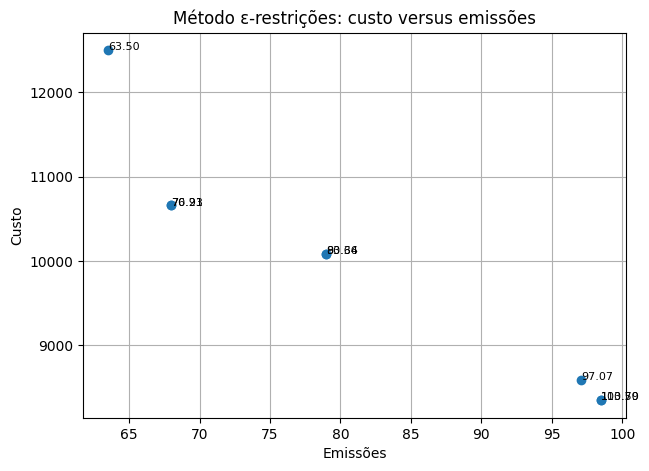

In [100]:
plt.figure(figsize=(7, 5))
plt.scatter(df_eps["emissoes"], df_eps["custo"])

for _, row in df_eps.iterrows():
    plt.text(row["emissoes"], row["custo"], row["nome"].replace("eps_emissoes_", ""), fontsize=8)

plt.xlabel("Emissões")
plt.ylabel("Custo")
plt.title("Método ε-restrições: custo versus emissões")
plt.grid(True)
plt.show()


# Parte IX — Programação por metas

Na programação por metas, o decisor define uma meta para cada critério.

Por exemplo:

- custo alvo: R$ 9000;
- emissões alvo: 80;
- risco alvo: 5.

O modelo introduz variáveis de desvio para medir o quanto cada meta foi ultrapassada.

Aqui vamos penalizar apenas desvios acima da meta, pois todos os critérios são de minimização.


In [103]:
metas = {
    "custo": 9000,
    "emissoes": 80,
    "risco": 5
}

pesos_metas = {
    "custo": 0.30,
    "emissoes": 0.60,
    "risco": 0.10
}


## Construção do modelo de programação por metas

Para cada objetivo, criamos duas variáveis de desvio:

$$
d_i^+ \geq 0
$$

desvio acima da meta;

$$
d_i^- \geq 0
$$

desvio abaixo da meta.

Para custo, por exemplo:

$$
Custo(x) + d_C^- - d_C^+ = Meta_C
$$

Se o custo ultrapassa a meta, $d_C^+$ fica positivo.

A função objetivo minimiza a soma ponderada dos desvios acima da meta.


In [104]:
def construir_modelo_programacao_metas(metas, pesos):
    m = construir_modelo_pim(relaxar_binarias=False)

    # Desvios para custo
    m.dmais_custo = pyo.Var(domain=pyo.NonNegativeReals)
    m.dmenos_custo = pyo.Var(domain=pyo.NonNegativeReals)

    # Desvios para emissões
    m.dmais_emissoes = pyo.Var(domain=pyo.NonNegativeReals)
    m.dmenos_emissoes = pyo.Var(domain=pyo.NonNegativeReals)

    # Desvios para risco
    m.dmais_risco = pyo.Var(domain=pyo.NonNegativeReals)
    m.dmenos_risco = pyo.Var(domain=pyo.NonNegativeReals)

    # Restrições de metas
    m.meta_custo = pyo.Constraint(
        expr=m.custo + m.dmenos_custo - m.dmais_custo == metas["custo"]
    )

    m.meta_emissoes = pyo.Constraint(
        expr=m.emissoes + m.dmenos_emissoes - m.dmais_emissoes == metas["emissoes"]
    )

    m.meta_risco = pyo.Constraint(
        expr=m.risco + m.dmenos_risco - m.dmais_risco == metas["risco"]
    )

    # Objetivo: minimizar desvios acima da meta
    m.obj = pyo.Objective(
        expr=(
            pesos["custo"] * m.dmais_custo +
            pesos["emissoes"] * m.dmais_emissoes +
            pesos["risco"] * m.dmais_risco
        ),
        sense=pyo.minimize
    )

    return m


## Resolver o modelo por metas

Vamos resolver o modelo e observar:

- valores finais de custo, emissões e risco;
- desvios acima das metas;
- linhas ativadas.

Isso ajuda a responder: quais metas foram atendidas e quais foram violadas?


In [106]:
m_metas = construir_modelo_programacao_metas(metas, pesos_metas)
resolver(m_metas)

display(tabela_solucao(m_metas))

print("Resultados:")
print(f"Custo: {pyo.value(m_metas.custo):.2f}")
print(f"Emissões: {pyo.value(m_metas.emissoes):.2f}")
print(f"Risco: {pyo.value(m_metas.risco):.2f}")

print("\nDesvios acima da meta:")
print(f"Custo: {pyo.value(m_metas.dmais_custo):.2f}")
print(f"Emissões: {pyo.value(m_metas.dmais_emissoes):.2f}")
print(f"Risco: {pyo.value(m_metas.dmais_risco):.2f}")

print("\nDesvios abaixo da meta:")
print(f"Custo: {pyo.value(m_metas.dmenos_custo):.2f}")
print(f"Emissões: {pyo.value(m_metas.dmenos_emissoes):.2f}")
print(f"Risco: {pyo.value(m_metas.dmenos_risco):.2f}")


,Linha,Produção x,Ativada y,Capacidade,Custo fixo,Custo variável,Emissão por unidade
0,L1_eficiente,0.0,-0.0,80,4500,42,0.55
1,L2_barata,60.0,1.0,70,2500,35,0.95
2,L3_flexivel,-0.0,-0.0,60,3200,48,0.65
3,L4_terceirizada,50.0,1.0,50,1000,60,0.80


Resultados:
Custo: 8600.00
Emissões: 97.00
Risco: 9.00

Desvios acima da meta:
Custo: 0.00
Emissões: 17.00
Risco: 4.00

Desvios abaixo da meta:
Custo: 400.00
Emissões: 0.00
Risco: 0.00


# Parte X — Dominância e fronteira de Pareto aproximada

Agora vamos juntar as soluções obtidas por:

- objetivos individuais;
- soma ponderada;
- $\varepsilon$-restrições;
- programação por metas.

Depois, vamos verificar quais soluções são dominadas e quais são não dominadas.

Em problemas de minimização, uma solução domina outra se:

1. é melhor ou igual em todos os objetivos;
2. é estritamente melhor em pelo menos um objetivo.


In [107]:
def domina(a, b, objetivos):
    melhor_ou_igual = all(a[obj] <= b[obj]  for obj in objetivos)
    estritamente_melhor = any(a[obj] < b[obj] for obj in objetivos)
    return melhor_ou_igual and estritamente_melhor


def marcar_nao_dominadas(df, objetivos):
    status = []

    for idx, linha in df.iterrows():
        dominada = False

        for jdx, outra in df.iterrows():
            if idx != jdx and domina(outra, linha, objetivos):
                dominada = True
                break

        status.append(not dominada)

    df = df.copy()
    df["nao_dominada"] = status
    return df


## Montando o conjunto de soluções

Vamos reunir todas as soluções geradas e aplicar o teste de dominância.

A tabela final mostra quais soluções fazem parte da fronteira de Pareto aproximada.


In [108]:
lista_resultados = []

# Soluções extremas
lista_resultados.extend(resultados_extremos)

# Soluções por pesos
lista_resultados.extend(solucoes_pesos)

# Soluções por epsilon
lista_resultados.extend(solucoes_eps)

# Solução por metas
lista_resultados.append(extrair_resultados(m_metas, "programacao_metas"))

df_todas = pd.DataFrame(lista_resultados)

# Remove soluções duplicadas por valores de objetivos
df_todas = df_todas.drop_duplicates(subset=["custo", "emissoes", "risco"]).reset_index(drop=True)

df_todas = marcar_nao_dominadas(df_todas, objetivos)

display(
    df_todas[["nome", "custo", "emissoes", "risco", "producao_total", "nao_dominada"]]
    .sort_values(["nao_dominada", "custo"], ascending=[False, True])
)


,nome,custo,emissoes,risco,producao_total,nao_dominada
0,min_custo,8350.000000,98.500000,9.0,110.0,True
6,eps_emissoes_97.07,8588.095238,97.071429,9.0,110.0,True
7,programacao_metas,8600.000000,97.000000,9.0,110.0,True
5,eps_emissoes_83.64,10080.000000,79.000000,9.0,110.0,True
3,foco_emissoes,10660.000000,68.000000,9.0,110.0,True
4,conservador_risco,11860.000000,84.000000,2.0,130.0,True
1,min_emissoes,12500.000000,63.500000,9.0,110.0,True
2,min_risco,12810.000000,110.500000,0.0,150.0,True


## Gráfico da fronteira de Pareto aproximada

Como temos três objetivos, é difícil visualizar tudo em um único gráfico 2D.

Vamos começar com um gráfico de **custo versus emissões**, marcando:

- soluções dominadas;
- soluções não dominadas.

O risco ainda será analisado na tabela e na discussão gerencial.


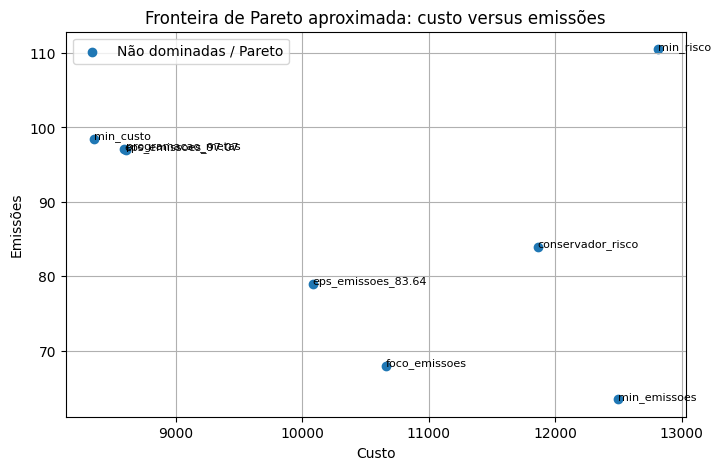

In [109]:
df_nd = df_todas[df_todas["nao_dominada"]].copy()
df_dom = df_todas[~df_todas["nao_dominada"]].copy()

plt.figure(figsize=(8, 5))

if len(df_dom) > 0:
    plt.scatter(df_dom["custo"], df_dom["emissoes"], label="Dominadas")

if len(df_nd) > 0:
    plt.scatter(df_nd["custo"], df_nd["emissoes"], label="Não dominadas / Pareto")

for _, row in df_nd.iterrows():
    plt.text(row["custo"], row["emissoes"], row["nome"], fontsize=8)

plt.xlabel("Custo")
plt.ylabel("Emissões")
plt.title("Fronteira de Pareto aproximada: custo versus emissões")
plt.legend()
plt.grid(True)
plt.show()


# Parte XII — Exercícios guiados

## Exercício 1 — Restrição “no máximo duas linhas”

Altere o modelo para permitir no máximo duas linhas ativadas:

$$
\sum_i y_i \leq 2
$$

Perguntas:

1. O custo aumenta?
2. As emissões mudam?
3. O risco aumenta?
4. Alguma solução torna-se inviável?

## Exercício 2 — Peso do risco

Na soma ponderada, crie um cenário com peso 0,70 para risco:

$$
w_R = 0{,}70
$$

Perguntas:

1. A produção total aumenta?
2. O custo aumenta?
3. A solução ficou mais conservadora?

## Exercício 3 — Limite de emissões

No método das $\varepsilon$-restrições, reduza progressivamente o limite de emissões.

Perguntas:

1. O custo aumenta?
2. O risco muda?
3. Em algum momento o problema fica inviável?

## Exercício 4 — Metas mais ambiciosas

Use metas mais difíceis:

```python
metas = {
    "custo": 6000,
    "emissoes": 60,
    "risco": 0
}
```

Perguntas:

1. Quais metas não foram atingidas?
2. Qual desvio ficou maior?
3. Os pesos mudam a solução?

## Exercício 5 — Big-M exagerado

Compare novamente a relaxação linear com Big-M realista e Big-M exagerado.

Perguntas:

1. A solução inteira mudou?
2. A relaxação linear mudou?
3. Os valores de $y_i$ ficaram menos realistas?


## Espaço para resolução dos exercícios

Use as funções já criadas:

- `construir_modelo_pim(...)`;
- `resolver(...)`;
- `construir_modelo_soma_ponderada(...)`;
- `construir_modelo_epsilon(...)`;
- `construir_modelo_programacao_metas(...)`.

Você pode copiar e adaptar células anteriores.


In [ ]:
# Exercício 1 — No máximo duas linhas
# Dica: use construir_modelo_pim(max_linhas=2)


In [ ]:
# Exercício 2 — Peso maior para risco
# Dica: crie um novo dicionário de pesos e resolva a soma ponderada.


In [ ]:
# Exercício 3 — Limite de emissões
# Dica: altere os valores de eps_emissoes no método epsilon-restrições.


In [ ]:
# Exercício 4 — Metas mais ambiciosas
# Dica: altere o dicionário metas e resolva novamente o modelo por metas.


In [ ]:
# Exercício 5 — Big-M exagerado
# Dica: compare relaxações lineares usando M realista e M exagerado.


# Conclusões da prática

Nesta prática, vimos que:

1. Programação Linear decide quantidades contínuas.
2. Programação Inteira Mista permite representar decisões discretas.
3. Variáveis binárias modelam escolhas do tipo sim/não.
4. Restrições Big-M ligam decisões binárias a variáveis contínuas.
5. Big-M deve ser escolhido com cuidado.
6. A relaxação linear ajuda a entender limites usados pelo Branch-and-Bound.
7. Em problemas multiobjetivo, não existe necessariamente uma única solução ótima.
8. Soluções não dominadas formam uma fronteira de Pareto aproximada.
9. Soma ponderada exige normalização para evitar distorções de escala.
10. $\varepsilon$-restrições são úteis quando o decisor sabe impor limites aceitáveis.
11. Programação por metas é útil quando há valores-alvo desejados.
12. A escolha final exige julgamento técnico e gerencial.

Mensagem final:

> Modelos de otimização não substituem a decisão gerencial. Eles organizam os trade-offs e ajudam a decidir com mais clareza.
